# Logistic Regression Baseline (Criteo DAC) — 1M-row chronological split

Goal: establish a **simple, interpretable baseline** before building an embedding-based DNN.

Key constraints:
- Use only the **first 1,000,000 labeled rows** from `train.txt` (fast iteration).
- Preserve the original **chronological ordering** (no shuffling before splitting).
- Learn all preprocessing parameters from **TRAIN only**.
- Do **not** use the competition `test.txt` for offline evaluation (it has no label).

We will: 
1) create a chronological train/val/test split (80/10/10)
2) report a constant-CTR baseline
3) build a sparse feature matrix with simple numeric + frequency-pruned one-hot categoricals
4) train logistic regression
5) evaluate and do a lightweight calibration/reliability analysis
6) inspect top coefficients


## 0. Setup
This notebook is designed to be readable and educational. We intentionally keep modeling decisions explicit and avoid hyperparameter searches.

In [1]:
from __future__ import annotations

import math
import warnings
from pathlib import Path

# Keep notebook output readable (baseline-focused).
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
try:
    from sklearn.exceptions import ConvergenceWarning
    warnings.filterwarnings('ignore', category=ConvergenceWarning)
except Exception:
    pass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, roc_auc_score, average_precision_score
from sklearn.preprocessing import OneHotEncoder
from scipy import sparse

%matplotlib inline

pd.set_option('display.max_columns', 80)
pd.set_option('display.width', 160)

# Paths: robust to running Jupyter from project root or notebooks/
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'criteo_advertising_dataset').exists():
    PROJECT_ROOT = Path('..').resolve()

DATA_DIR = PROJECT_ROOT / 'criteo_advertising_dataset'
TRAIN_PATH = DATA_DIR / 'train.txt'
README_PATH = DATA_DIR / 'readme.txt'

SAMPLE_N = 1_000_000
RANDOM_SEED = 42  # only used if any stochastic solver behavior appears

CLIP_UPPER_Q = 0.999  # train-only upper clip for non-negative count features
MIN_FREQ = 10  # frequency threshold for categorical pruning (train-only); easy to change
MISSING_TOKEN = '__MISSING__'
OOV_TOKEN = '__OTHER__'


## 1. Dataset structure (confirm from documentation)
We re-check the official `readme.txt` so we don't accidentally assume the schema.

In [2]:
readme_text = README_PATH.read_text(encoding='utf-8', errors='replace')
print(readme_text)
print()
print('Doc mentions chronological order:', 'chronologically ordered' in readme_text.lower())

        ------ Display Advertising Challenge ------

Dataset: dac-v1

This dataset contains feature values and click feedback for millions of display 
ads. Its purpose is to benchmark algorithms for clickthrough rate (CTR) prediction.
It has been used for the Display Advertising Challenge hosted by Kaggle:
https://www.kaggle.com/c/criteo-display-ad-challenge/


Full description:

This dataset contains 2 files:
  train.txt
  test.txt
corresponding to the training and test parts of the data. 


Dataset construction:

The training dataset consists of a portion of Criteo's traffic over a period
of 7 days. Each row corresponds to a display ad served by Criteo and the first
column is indicates whether this ad has been clicked or not.
The positive (clicked) and negatives (non-clicked) examples have both been
subsampled (but at different rates) in order to reduce the dataset size.

There are 13 features taking integer values (mostly count features) and 26
categorical features. The values of th

### Schema
- `train.txt` columns: `label` + 13 integer features `I1..I13` + 26 categorical features `C1..C26`
- `test.txt` has no label (so we don’t use it for offline evaluation)

The categorical features are hashed/anonymized in the Criteo dataset, so we treat them as opaque identifiers.

In [3]:
NUM_INT_FEATURES = 13
NUM_CAT_FEATURES = 26

numeric_cols = [f'I{i}' for i in range(1, NUM_INT_FEATURES + 1)]
cat_cols = [f'C{i}' for i in range(1, NUM_CAT_FEATURES + 1)]
columns = ['label'] + numeric_cols + cat_cols

pd.DataFrame({
    'split': ['train'],
    'label_col': ['label'],
    'num_numeric_features': [len(numeric_cols)],
    'num_categorical_features': [len(cat_cols)],
    'total_columns': [len(columns)],
})

,split,label_col,num_numeric_features,num_categorical_features,total_columns
0,train,label,13,26,40


## 2. Load first 1,000,000 labeled rows (no full scan)
We load only a subset for iteration speed. All reported metrics are computed on this 1M-row slice and its chronological split.

In [4]:
# Memory-conscious dtypes: label int8, numeric float32; categoricals kept as object and cleaned later.
dtype = {'label': 'int8', **{c: 'float32' for c in numeric_cols}}

df = pd.read_csv(
    TRAIN_PATH,
    sep='	',
    header=None,
    names=columns,
    nrows=SAMPLE_N,
    dtype=dtype,
    low_memory=False,
)

df.head()

,label,I1,I2,I3,I4,I5,I6,I7,I8,I9,I10,I11,I12,I13,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,C14,C15,C16,C17,C18,C19,C20,C21,C22,C23,C24,C25,C26
0,0,1.0,1.0,5.0,0.0,1382.0,4.0,15.0,2.0,181.0,1.0,2.0,NaN,2.0,68fd1e64,80e26c9b,fb936136,7b4723c4,25c83c98,7e0ccccf,de7995b8,1f89b562,a73ee510,a8cd5504,b2cb9c98,37c9c164,2824a5f6,1adce6ef,8ba8b39a,891b62e7,e5ba7672,f54016b9,21ddcdc9,b1252a9d,07b5194c,NaN,3a171ecb,c5c50484,e8b83407,9727dd16
1,0,2.0,0.0,44.0,1.0,102.0,8.0,2.0,2.0,4.0,1.0,1.0,NaN,4.0,68fd1e64,f0cf0024,6f67f7e5,41274cd7,25c83c98,fe6b92e5,922afcc0,0b153874,a73ee510,2b53e5fb,4f1b46f3,623049e6,d7020589,b28479f6,e6c5b5cd,c92f3b61,07c540c4,b04e4670,21ddcdc9,5840adea,60f6221e,NaN,3a171ecb,43f13e8b,e8b83407,731c3655
2,0,2.0,0.0,1.0,14.0,767.0,89.0,4.0,2.0,245.0,1.0,3.0,3.0,45.0,287e684f,0a519c5c,02cf9876,c18be181,25c83c98,7e0ccccf,c78204a1,0b153874,a73ee510,3b08e48b,5f5e6091,8fe001f4,aa655a2f,07d13a8f,6dc710ed,36103458,8efede7f,3412118d,NaN,NaN,e587c466,ad3062eb,3a171ecb,3b183c5c,NaN,NaN
3,0,NaN,893.0,NaN,NaN,4392.0,NaN,0.0,0.0,0.0,NaN,0.0,NaN,NaN,68fd1e64,2c16a946,a9a87e68,2e17d6f6,25c83c98,fe6b92e5,2e8a689b,0b153874,a73ee510,efea433b,e51ddf94,a30567ca,3516f6e6,07d13a8f,18231224,52b8680f,1e88c74f,74ef3502,NaN,NaN,6b3a5ca6,NaN,3a171ecb,9117a34a,NaN,NaN
4,0,3.0,-1.0,NaN,0.0,2.0,0.0,3.0,0.0,0.0,1.0,1.0,NaN,0.0,8cf07265,ae46a29d,c81688bb,f922efad,25c83c98,13718bbd,ad9fa255,0b153874,a73ee510,5282c137,e5d8af57,66a76a26,f06c53ac,1adce6ef,8ff4b403,01adbab4,1e88c74f,26b3c7a7,NaN,NaN,21c9516a,NaN,32c7478e,b34f3128,NaN,NaN


## 3. Chronological split (80/10/10)
We preserve the existing row order to approximate **training on past traffic and evaluating on future traffic**.

We intentionally do **not** shuffle before splitting.

In [5]:
N = len(df)
n_train = int(0.80 * N)
n_val = int(0.10 * N)
n_test = N - n_train - n_val

df_train = df.iloc[:n_train].copy()
df_val = df.iloc[n_train:n_train + n_val].copy()
df_test = df.iloc[n_train + n_val:].copy()

def ctr(y: np.ndarray) -> float:
    return float(np.mean(y))

y_train = df_train['label'].to_numpy()
y_val = df_val['label'].to_numpy()
y_test = df_test['label'].to_numpy()

pd.DataFrame({
    'split': ['train', 'val', 'test'],
    'rows': [len(df_train), len(df_val), len(df_test)],
    'ctr': [ctr(y_train), ctr(y_val), ctr(y_test)],
})

,split,rows,ctr
0,train,800000,0.255895
1,val,100000,0.252070
2,test,100000,0.250260


## 4. Constant CTR baseline (train-only mean)
Before fitting any model, we establish a naive baseline:
- estimate mean CTR on TRAIN
- predict that same probability for every validation/test observation

This is a useful sanity check: a learned model must beat it.

In [6]:
p_train = float(np.mean(y_train))

def eval_metrics(y_true: np.ndarray, y_prob: np.ndarray) -> dict:
    # log_loss expects probabilities in (0,1); clip for numeric safety
    y_prob = np.clip(y_prob, 1e-6, 1 - 1e-6)
    return {
        'logloss': float(log_loss(y_true, y_prob)),
        'roc_auc': float(roc_auc_score(y_true, y_prob)),
        'pr_auc': float(average_precision_score(y_true, y_prob)),
    }

train_const = eval_metrics(y_train, np.full_like(y_train, p_train, dtype=float))
val_const = eval_metrics(y_val, np.full_like(y_val, p_train, dtype=float))
test_const = eval_metrics(y_test, np.full_like(y_test, p_train, dtype=float))

pd.DataFrame({
    'split': ['train', 'val', 'test'],
    'logloss': [train_const['logloss'], val_const['logloss'], test_const['logloss']],
    'roc_auc': [train_const['roc_auc'], val_const['roc_auc'], test_const['roc_auc']],
    'pr_auc': [train_const['pr_auc'], val_const['pr_auc'], test_const['pr_auc']],
})

,split,logloss,roc_auc,pr_auc
0,train,0.568719,0.5,0.255895
1,val,0.564636,0.5,0.252070
2,test,0.562704,0.5,0.250260


## 5. Preprocessing (train-only fit)
We build a sparse feature representation suitable for logistic regression.

### Numerical features
Two groups, decided from TRAIN:
- **Non-negative counts** (I1, I3–I13): clip to `[0, p99.9]` → `log1p` → standardize
- **Signed** (I2, has legitimate negatives): standardize only (no clamp, no log)

Missing values:
- stay `NaN` through clip / log1p / standardize (they never become fake values like `-1` or `0` mid-pipeline)
- mean/std are computed on **non-missing TRAIN values only**
- after standardization, `NaN → 0` (= the train mean, a neutral value) **plus** a binary `I{k}_missing` column, so LR learns a separate weight for missingness (which is frequent and informative in Criteo)

All parameters (clip thresholds, means, stds) are learned on TRAIN and frozen for val/test. We assert the final matrices are finite rather than silently patching bad values.

### Categorical features
We do frequency-pruned one-hot encoding (sparse):
- missing -> `__MISSING__`
- rare categories (freq < MIN_FREQ) -> `__OTHER__`
- validation/test unseen categories -> `__OTHER__`

This is a baseline v1; we avoid target encoding and do not tune `MIN_FREQ` extensively.

In [7]:
# --- Numerical preprocessing plan (TRAIN ONLY) ---
# Criteo integer features are counts; every non-negative one gets clip + log1p.
# Features with legitimate negative values are only standardized.

def choose_numeric_transforms(df_train: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    rows = []
    for c in cols:
        s = df_train[c]
        has_neg = bool((s.dropna() < 0).any())
        rows.append({
            'feature': c,
            'has_negative_values_in_train': has_neg,
            'clip_0_to_train_quantile': not has_neg,
            'apply_log1p': not has_neg,
            'missing_rate_train': float(s.isna().mean()),
        })
    return pd.DataFrame(rows)

numeric_plan = choose_numeric_transforms(df_train, numeric_cols)
numeric_plan

,feature,has_negative_values_in_train,clip_0_to_train_quantile,apply_log1p,missing_rate_train
0,I1,False,True,True,0.422659
1,I2,True,False,False,0.000000
2,I3,False,True,True,0.236276
3,I4,False,True,True,0.253134
4,I5,False,True,True,0.025615
5,I6,False,True,True,0.222959
6,I7,False,True,True,0.041275
7,I8,False,True,True,0.000692
8,I9,False,True,True,0.041275
9,I10,False,True,True,0.422659


In [8]:
# --- Fit numeric parameters using TRAIN-only, non-missing values ---

def pre_standardize(s: pd.Series, p: dict) -> pd.Series:
    # NaN stays NaN through clip and log1p (pandas propagates it).
    if p['clip_upper'] is not None:
        s = s.clip(lower=0, upper=p['clip_upper'])
    if p['apply_log1p']:
        s = np.log1p(s)
    return s

def fit_numeric_params(df_train: pd.DataFrame, plan: pd.DataFrame) -> dict:
    params = {}
    for _, row in plan.iterrows():
        c = row['feature']
        s = df_train[c]
        p = {
            'apply_log1p': bool(row['apply_log1p']),
            'clip_upper': float(s.quantile(CLIP_UPPER_Q)) if row['clip_0_to_train_quantile'] else None,
        }
        t = pre_standardize(s, p)
        # pandas mean/std skip NaN -> statistics come from non-missing values only
        mean, std = float(t.mean()), float(t.std(ddof=0))
        if not (np.isfinite(mean) and np.isfinite(std)):
            raise ValueError(f'{c}: non-finite train statistics (mean={mean}, std={std})')
        p['mean'] = mean
        p['std'] = std if std > 0 else 1.0
        params[c] = p
    return params

numeric_params = fit_numeric_params(df_train, numeric_plan)
pd.DataFrame(numeric_params).T

,apply_log1p,clip_upper,mean,std
I1,True,102.127998,0.815718,0.956668
I2,False,None,90.995621,340.393158
I3,True,1581.021973,2.015459,1.128538
I4,True,62.0,1.67079,0.872359
I5,True,838537.5625,7.467155,2.778455
I6,True,3918.840088,3.413654,1.743602
I7,True,773.020996,1.576781,1.350367
I8,True,49.0,2.089091,1.160956
I9,True,2490.020996,3.558785,1.620554
I10,True,4.0,0.365796,0.400384


In [9]:
def transform_numeric(df: pd.DataFrame, cols: list[str], params: dict) -> np.ndarray:
    # Output: [standardized values (NaN -> 0) | missing indicators]
    X = np.zeros((len(df), 2 * len(cols)), dtype=np.float32)
    for j, c in enumerate(cols):
        p = params[c]
        z = (pre_standardize(df[c], p) - p['mean']) / p['std']
        is_missing = z.isna()
        X[:, j] = z.fillna(0.0).to_numpy(dtype=np.float32)
        X[:, len(cols) + j] = is_missing.to_numpy(dtype=np.float32)
    if not np.isfinite(X).all():
        raise ValueError('Non-finite values in numeric features after preprocessing')
    return X

numeric_feature_names = numeric_cols + [f'{c}_missing' for c in numeric_cols]

X_num_train = transform_numeric(df_train, numeric_cols, numeric_params)
X_num_val = transform_numeric(df_val, numeric_cols, numeric_params)
X_num_test = transform_numeric(df_test, numeric_cols, numeric_params)

X_num_train.shape, X_num_val.shape, X_num_test.shape

((800000, 26), (100000, 26), (100000, 26))

In [10]:
# --- Categorical preprocessing (TRAIN ONLY) ---

def fit_category_vocabularies(df_train: pd.DataFrame, cols: list[str], min_freq: int) -> tuple[dict, pd.DataFrame]:
    vocab = {}
    rows = []
    n = len(df_train)
    for c in cols:
        s = df_train[c].astype('object')
        s = s.where(~s.isna(), MISSING_TOKEN)

        counts = s.value_counts(dropna=False)
        original_V = int(counts.shape[0])

        kept = set(counts[counts >= min_freq].index.tolist())
        # Ensure missing token always exists as a dedicated category
        kept.add(MISSING_TOKEN)

        pruned_V = len(kept)
        # Use reindex(..., fill_value=0) so we can include tokens (like __MISSING__) even if
        # they don't appear in the 1M TRAIN slice for a particular feature.
        coverage = float(counts.reindex(list(kept), fill_value=0).sum() / n) if pruned_V > 0 else 0.0

        vocab[c] = kept
        rows.append({
            'feature': c,
            'original_train_cardinality': original_V,
            'cardinality_after_pruning': pruned_V,
            'train_row_coverage_retained': coverage,
        })
    return vocab, pd.DataFrame(rows).sort_values('feature').reset_index(drop=True)

cat_vocab, cat_vocab_summary = fit_category_vocabularies(df_train, cat_cols, MIN_FREQ)
cat_vocab_summary.head()

,feature,original_train_cardinality,cardinality_after_pruning,train_row_coverage_retained
0,C1,1185,282,0.996789
1,C10,28255,6428,0.931125
2,C11,4658,3493,0.994321
3,C12,222451,5373,0.644652
4,C13,3058,2724,0.997965


In [11]:
# Print full per-feature categorical pruning summary (train-only)
cat_vocab_summary

,feature,original_train_cardinality,cardinality_after_pruning,train_row_coverage_retained
0,C1,1185,282,0.996789
1,C10,28255,6428,0.931125
2,C11,4658,3493,0.994321
3,C12,222451,5373,0.644652
4,C13,3058,2724,0.997965
5,C14,26,26,0.999990
6,C15,8578,3816,0.981272
7,C16,172322,5578,0.708882
8,C17,10,11,1.000000
9,C18,3763,2010,0.992686


In [12]:
def apply_categorical_mapping(df: pd.DataFrame, cols: list[str], vocab: dict) -> pd.DataFrame:
    out = pd.DataFrame(index=df.index)
    for c in cols:
        s = df[c].astype('object')
        s = s.where(~s.isna(), MISSING_TOKEN)
        kept = vocab[c]
        out[c] = s.where(s.isin(kept), OOV_TOKEN)
    return out

X_cat_train_df = apply_categorical_mapping(df_train, cat_cols, cat_vocab)
X_cat_val_df = apply_categorical_mapping(df_val, cat_cols, cat_vocab)
X_cat_test_df = apply_categorical_mapping(df_test, cat_cols, cat_vocab)

X_cat_train_df.head()

,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,C14,C15,C16,C17,C18,C19,C20,C21,C22,C23,C24,C25,C26
0,68fd1e64,80e26c9b,__OTHER__,7b4723c4,25c83c98,7e0ccccf,de7995b8,1f89b562,a73ee510,a8cd5504,b2cb9c98,__OTHER__,2824a5f6,1adce6ef,8ba8b39a,__OTHER__,e5ba7672,f54016b9,21ddcdc9,b1252a9d,__OTHER__,__MISSING__,3a171ecb,c5c50484,e8b83407,9727dd16
1,68fd1e64,f0cf0024,6f67f7e5,41274cd7,25c83c98,fe6b92e5,922afcc0,0b153874,a73ee510,2b53e5fb,4f1b46f3,623049e6,d7020589,b28479f6,e6c5b5cd,c92f3b61,07c540c4,b04e4670,21ddcdc9,5840adea,60f6221e,__MISSING__,3a171ecb,43f13e8b,e8b83407,731c3655
2,287e684f,0a519c5c,02cf9876,c18be181,25c83c98,7e0ccccf,c78204a1,0b153874,a73ee510,3b08e48b,5f5e6091,8fe001f4,aa655a2f,07d13a8f,6dc710ed,36103458,8efede7f,3412118d,__MISSING__,__MISSING__,e587c466,ad3062eb,3a171ecb,3b183c5c,__MISSING__,__MISSING__
3,68fd1e64,2c16a946,__OTHER__,2e17d6f6,25c83c98,fe6b92e5,2e8a689b,0b153874,a73ee510,efea433b,e51ddf94,__OTHER__,3516f6e6,07d13a8f,18231224,__OTHER__,1e88c74f,74ef3502,__MISSING__,__MISSING__,__OTHER__,__MISSING__,3a171ecb,9117a34a,__MISSING__,__MISSING__
4,8cf07265,ae46a29d,__OTHER__,f922efad,25c83c98,13718bbd,ad9fa255,0b153874,a73ee510,5282c137,e5d8af57,66a76a26,f06c53ac,1adce6ef,8ff4b403,01adbab4,1e88c74f,26b3c7a7,__MISSING__,__MISSING__,21c9516a,__MISSING__,32c7478e,b34f3128,__MISSING__,__MISSING__


In [13]:
# One-hot encode categoricals (sparse).
# handle_unknown='ignore' ensures truly unseen categories (should be rare due to OOV mapping) are safely ignored.
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=True)

X_cat_train = ohe.fit_transform(X_cat_train_df)
X_cat_val = ohe.transform(X_cat_val_df)
X_cat_test = ohe.transform(X_cat_test_df)

X_cat_train.shape, X_cat_val.shape, X_cat_test.shape

((800000, 63611), (100000, 63611), (100000, 63611))

In [14]:
# Combine numeric (dense) + categorical (sparse) into a single sparse matrix
X_train = sparse.hstack([sparse.csr_matrix(X_num_train), X_cat_train], format='csr')
X_val = sparse.hstack([sparse.csr_matrix(X_num_val), X_cat_val], format='csr')
X_test = sparse.hstack([sparse.csr_matrix(X_num_test), X_cat_test], format='csr')

for name, X in [('train', X_train), ('val', X_val), ('test', X_test)]:
    if not np.isfinite(X.data).all():
        raise ValueError(f'{name}: feature matrix contains NaN/inf')

X_train.shape, X_val.shape, X_test.shape

((800000, 63637), (100000, 63637), (100000, 63637))

## 6. Logistic Regression
We fit a binary logistic regression model to estimate **P(click | features)**.

Important modeling choice (baseline v1):
- no class weights
- no over/under-sampling

We use a solver suitable for large, sparse matrices (`saga`).

In [15]:
lr = LogisticRegression(
    solver='saga',
    penalty='l2',
    C=1.0,
    max_iter=100,
    n_jobs=-1,
    random_state=RANDOM_SEED,
)

lr.fit(X_train, y_train)

# Predict probabilities (train included to check for overfitting: compare train vs val)
p_train_lr = lr.predict_proba(X_train)[:, 1]
p_val_lr = lr.predict_proba(X_val)[:, 1]
p_test_lr = lr.predict_proba(X_test)[:, 1]

train_lr = eval_metrics(y_train, p_train_lr)
val_lr = eval_metrics(y_val, p_val_lr)
test_lr = eval_metrics(y_test, p_test_lr)

pd.DataFrame({
    'split': ['train', 'val', 'test'],
    'logloss': [train_lr['logloss'], val_lr['logloss'], test_lr['logloss']],
    'roc_auc': [train_lr['roc_auc'], val_lr['roc_auc'], test_lr['roc_auc']],
    'pr_auc': [train_lr['pr_auc'], val_lr['pr_auc'], test_lr['pr_auc']],
})

,split,logloss,roc_auc,pr_auc
0,train,0.445272,0.806641,0.607428
1,val,0.462638,0.781979,0.564447
2,test,0.461058,0.781964,0.561657


## 7. Calibration / reliability analysis (validation)
For CTR modeling, probability calibration matters (e.g., bidding / ranking decisions).

We bucket predictions into bins and compare:
- mean predicted CTR
- observed CTR
- number of observations

This is a lightweight reliability diagram (not a full calibration study).

In [16]:
def calibration_table(y_true: np.ndarray, y_prob: np.ndarray, n_bins: int = 10) -> pd.DataFrame:
    dfc = pd.DataFrame({'y': y_true, 'p': y_prob})
    dfc['bin'] = pd.cut(dfc['p'], bins=np.linspace(0, 1, n_bins + 1), include_lowest=True)
    out = (
        dfc.groupby('bin', observed=False)
        .agg(n=('y', 'size'), mean_pred=('p', 'mean'), obs_ctr=('y', 'mean'))
        .reset_index()
    )
    return out

cal_val = calibration_table(y_val, p_val_lr, n_bins=10)
cal_val

,bin,n,mean_pred,obs_ctr
0,"(-0.001, 0.1]",26125,0.057228,0.059407
1,"(0.1, 0.2]",24667,0.146839,0.146390
2,"(0.2, 0.3]",16448,0.246812,0.247750
3,"(0.3, 0.4]",10955,0.347033,0.343131
4,"(0.4, 0.5]",7688,0.446963,0.434964
5,"(0.5, 0.6]",5633,0.547334,0.517131
6,"(0.6, 0.7]",3867,0.647594,0.626843
7,"(0.7, 0.8]",2692,0.745552,0.705423
8,"(0.8, 0.9]",1528,0.843573,0.831152
9,"(0.9, 1.0]",397,0.927597,0.906801


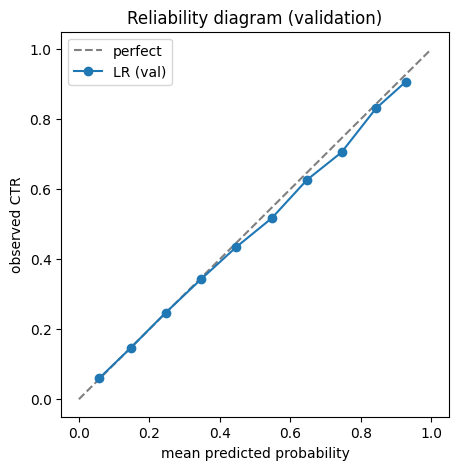

In [17]:
plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], '--', color='gray', label='perfect')
plt.plot(cal_val['mean_pred'], cal_val['obs_ctr'], marker='o', label='LR (val)')
plt.xlabel('mean predicted probability')
plt.ylabel('observed CTR')
plt.title('Reliability diagram (validation)')
plt.legend()
plt.show()

## 8. Model interpretation (lightweight)
We avoid over-interpreting anonymized features. Still, we can inspect which engineered tokens have large positive/negative coefficients.

In [18]:
n_features = X_train.shape[1]
coef = lr.coef_.ravel()
n_nonzero = int(np.count_nonzero(coef))

# Build feature names: numeric + one-hot names
ohe_feature_names = ohe.get_feature_names_out(cat_cols)
feature_names = np.concatenate([np.array(numeric_feature_names, dtype=object), ohe_feature_names])

pd.DataFrame({
    'num_features_total': [n_features],
    'num_nonzero_coefficients': [n_nonzero],
    'min_freq_for_onehot': [MIN_FREQ],
})

,num_features_total,num_nonzero_coefficients,min_freq_for_onehot
0,63637,63636,10


In [19]:
# Top coefficients
top_k = 15
idx_sorted = np.argsort(coef)

largest_negative = pd.DataFrame({
    'feature': feature_names[idx_sorted[:top_k]],
    'coef': coef[idx_sorted[:top_k]],
})

largest_positive = pd.DataFrame({
    'feature': feature_names[idx_sorted[-top_k:]][::-1],
    'coef': coef[idx_sorted[-top_k:]][::-1],
})

display(largest_positive)
display(largest_negative)

,feature,coef
0,C13_61537f27,1.617909
1,C24_e5c2573e,1.418435
2,C12_977d7916,1.343795
3,C3_6dd570f4,1.303321
4,C18_87c9f30d,1.284955
5,C10_f1b45aab,1.194795
6,C26_496b82a5,1.193210
7,C26_b3606536,1.179574
8,C15_7de4908b,1.070642
9,C15_50340d14,0.995450


,feature,coef
0,C14_26ac7cf4,-1.429012
1,C7_c1bec383,-1.332253
2,C14_8ceecbc8,-1.278994
3,C7_12343fcc,-1.230652
4,C15_dcd06253,-1.168441
5,C18_0ad1cc71,-1.018353
6,C7_315c76f3,-1.002710
7,C26_56009c93,-0.929308
8,C15_2d0bb053,-0.920544
9,C14_f862f261,-0.878442


## 9. Summary
We compare the logistic regression model against the constant CTR baseline.

In [20]:
summary = pd.DataFrame({
    'metric': [
        'Train LogLoss', 'Train ROC-AUC', 'Train PR-AUC',
        'Validation LogLoss', 'Validation ROC-AUC', 'Validation PR-AUC',
        'Test LogLoss', 'Test ROC-AUC', 'Test PR-AUC',
    ],
    'Constant Baseline': [
        train_const['logloss'], train_const['roc_auc'], train_const['pr_auc'],
        val_const['logloss'], val_const['roc_auc'], val_const['pr_auc'],
        test_const['logloss'], test_const['roc_auc'], test_const['pr_auc'],
    ],
    'Logistic Regression': [
        train_lr['logloss'], train_lr['roc_auc'], train_lr['pr_auc'],
        val_lr['logloss'], val_lr['roc_auc'], val_lr['pr_auc'],
        test_lr['logloss'], test_lr['roc_auc'], test_lr['pr_auc'],
    ],
})
# Train-vs-val gap: a large gap would indicate overfitting
summary['LR gap (train - val)'] = np.nan
for m in ['LogLoss', 'ROC-AUC', 'PR-AUC']:
    gap = summary.loc[summary.metric == f'Train {m}', 'Logistic Regression'].item() - summary.loc[summary.metric == f'Validation {m}', 'Logistic Regression'].item()
    summary.loc[summary.metric == f'Train {m}', 'LR gap (train - val)'] = gap
summary

,metric,Constant Baseline,Logistic Regression,LR gap (train - val)
0,Train LogLoss,0.568719,0.445272,-0.017366
1,Train ROC-AUC,0.500000,0.806641,0.024662
2,Train PR-AUC,0.255895,0.607428,0.042981
3,Validation LogLoss,0.564636,0.462638,NaN
4,Validation ROC-AUC,0.500000,0.781979,NaN
5,Validation PR-AUC,0.252070,0.564447,NaN
6,Test LogLoss,0.562704,0.461058,NaN
7,Test ROC-AUC,0.500000,0.781964,NaN
8,Test PR-AUC,0.250260,0.561657,NaN


### Questions before building the DNN
- How much did LR improve over the constant CTR baseline?
- Is ranking performance (ROC-AUC / PR-AUC) meaningfully better?
- How well calibrated are probabilities (reliability diagram)?
- Where does a linear model appear limited (feature interactions, non-linearities)?
- What could embeddings + nonlinear interactions add?

(We intentionally stop here — no DNN yet.)